In [1]:
import pandas as pd
from pathlib import Path
import copy
import math

# 1: Trial and error

In [2]:
PROJECT_PATH = Path.cwd().parent
METHU_PATH = Path(f"{PROJECT_PATH}/methu_txt")
OUT_PATH = Path(f"{PROJECT_PATH}/out_txt")

print(PROJECT_PATH, "\n", METHU_PATH, "\n", OUT_PATH)

c:\Users\csaba\OneDrive\Asztali gép\info\fisher_informacio 
 c:\Users\csaba\OneDrive\Asztali gép\info\fisher_informacio\methu_txt 
 c:\Users\csaba\OneDrive\Asztali gép\info\fisher_informacio\out_txt


In [3]:
df_tigge = pd.DataFrame(columns=["datum","d_ta","d_tx","d_tn","d_rs"])
df_methu = df_tigge.copy()

In [4]:
print("Betöltöm a Met.hu méréseit...")
with open(f"{METHU_PATH}/BP_d.txt", "r") as file_m:
    sorok = file_m.readlines()
    sorok.pop(0)
    for sor in sorok:
        adatsor = sor.split(";")
        df_methu.loc[len(df_methu)] = [adatsor[0],float(adatsor[1]),float(adatsor[2]), float(adatsor[3]), float(adatsor[4])]
print("Kész!")

print("Betöltöm a Tigge méréseit...")
with open(f"{OUT_PATH}/Budapest_final.txt", "r") as file_t:
    sorok = file_t.readlines()
    sorok.pop(0)
    for sor in sorok:
        adatsor = sor.strip().split(';')
        df_tigge.loc[len(df_tigge)] = [adatsor[0],float(adatsor[1]),float(adatsor[2]), float(adatsor[3]), float(adatsor[4])]
print("Kész!")

Betöltöm a Met.hu méréseit...
Kész!
Betöltöm a Tigge méréseit...
Kész!


In [5]:
print(df_tigge.head(3))
print('--')
print(df_methu.head(3))

        datum  d_ta  d_tx  d_tn  d_rs
0  2006-10-01  17.4  23.4  11.3   0.0
1  2006-10-02  17.6  23.0  12.2   0.0
2  2006-10-03  20.6  24.7  16.5   2.9
--
        datum  d_ta  d_tx  d_tn  d_rs
0  2006-10-01  18.5  24.7  12.9   0.0
1  2006-10-02  19.5  25.1  14.5   0.0
2  2006-10-03  21.1  26.7  15.4   0.0


In [6]:
merged = df_methu.merge(df_tigge, on="datum", how="inner", suffixes=("_tigge", "_methu") )

print("Összeillesztett dataframe:")
merged.head(10)

Összeillesztett dataframe:


,datum,d_ta_tigge,d_tx_tigge,d_tn_tigge,d_rs_tigge,d_ta_methu,d_tx_methu,d_tn_methu,d_rs_methu
0,2006-10-01,18.5,24.7,12.9,0.0,17.4,23.4,11.3,0.0
1,2006-10-02,19.5,25.1,14.5,0.0,17.6,23.0,12.2,0.0
2,2006-10-03,21.1,26.7,15.4,0.0,20.6,24.7,16.5,2.9
3,2006-10-04,17.7,23.9,15.6,0.0,18.4,22.5,14.4,0.2
4,2006-10-05,15.7,19.1,13.2,0.0,15.6,18.7,12.5,0.0
5,2006-10-06,14.4,19.8,10.9,0.0,13.1,17.6,8.5,0.0
6,2006-10-07,14.0,21.2,7.7,0.3,12.4,18.3,6.5,0.1
7,2006-10-08,15.2,19.9,12.2,0.0,13.6,18.3,8.9,0.0
8,2006-10-09,14.2,21.6,8.4,0.0,11.9,18.3,5.5,0.0
9,2006-10-10,14.7,22.2,9.4,0.0,12.5,19.2,5.8,0.0


In [7]:
print("Nézzük a különbségeket:")

for adat in ["d_ta", "d_tx", "d_tn", "d_rs"]:
    print(merged[f"{adat}_methu"],merged[f"{adat}_tigge"])
    merged[f"{adat}_diff"] = merged[f"{adat}_tigge"] - merged[f"{adat}_methu"]

Nézzük a különbségeket:
0       17.4
1       17.6
2       20.6
3       18.4
4       15.6
        ... 
6266     2.2
6267     1.3
6268    -0.2
6269    -0.9
6270    -1.4
Name: d_ta_methu, Length: 6271, dtype: float64 0       18.5
1       19.5
2       21.1
3       17.7
4       15.7
        ... 
6266     2.2
6267     2.2
6268    -0.3
6269    -1.1
6270    -1.7
Name: d_ta_tigge, Length: 6271, dtype: float64
0       23.4
1       23.0
2       24.7
3       22.5
4       18.7
        ... 
6266     6.4
6267     5.1
6268     3.3
6269     2.0
6270    -0.5
Name: d_tx_methu, Length: 6271, dtype: float64 0       24.7
1       25.1
2       26.7
3       23.9
4       19.1
        ... 
6266     2.2
6267     2.2
6268    -0.3
6269    -1.1
6270    -1.7
Name: d_tx_tigge, Length: 6271, dtype: float64
0       11.3
1       12.2
2       16.5
3       14.4
4       12.5
        ... 
6266    -2.0
6267    -2.5
6268    -3.6
6269    -3.8
6270    -2.2
Name: d_tn_methu, Length: 6271, dtype: float64 0       12.9
1       14.5


Ez így nem lesz jó, több hiba is előjön, nézzünk egy másik megoldást

In [8]:
def read_file(path):

    df = pd.read_csv(path, sep=";", skiprows=1, header = None, usecols = range(5), names=["datum", "d_ta", "d_tx", "d_tn", "d_rs"] )
    
    df["datum"] = pd.to_datetime(df["datum"])
    for col in ["d_ta", "d_tx", "d_tn", "d_rs"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

In [9]:
df_methu = read_file(f"{METHU_PATH}/BP_d.txt")
df_tigge = read_file(f"{OUT_PATH}/Budapest_final.txt")

print(df_methu.head(3))
print("--")
print(df_tigge.head(3))

       datum  d_ta  d_tx  d_tn  d_rs
0 2006-10-01  18.5  24.7  12.9   0.0
1 2006-10-02  19.5  25.1  14.5   0.0
2 2006-10-03  21.1  26.7  15.4   0.0
--
       datum  d_ta  d_tx  d_tn  d_rs
0 2006-10-01  17.4  23.4  11.3   0.0
1 2006-10-02  17.6  23.0  12.2   0.0
2 2006-10-03  20.6  24.7  16.5   2.9


In [10]:
print(df_methu.isna().sum())
print(df_tigge.isna().sum())

datum    0
d_ta     0
d_tx     0
d_tn     0
d_rs     0
dtype: int64
datum    0
d_ta     0
d_tx     0
d_tn     0
d_rs     0
dtype: int64


In [11]:
merged = df_tigge.merge(df_methu, on="datum", how="inner", suffixes=("_tigge", "_methu"))

for adat in ["d_ta", "d_tx", "d_tn", "d_rs"]:
    merged[f"{adat}_diff"] = merged[f"{adat}_tigge"] - merged[f"{adat}_methu"]

print(f"Tigge: {len(df_tigge)}, Methu: {len(df_methu)}, Összekapcsolt: {len(merged)}")
print("duplikált dátum:", merged["datum"].duplicated().sum())
print(merged.dtypes)
print(merged.filter(like="_diff").describe())

Tigge: 6271, Methu: 7032, Összekapcsolt: 6271
duplikált dátum: 0
datum         datetime64[us]
d_ta_tigge           float64
d_tx_tigge           float64
d_tn_tigge           float64
d_rs_tigge           float64
d_ta_methu           float64
d_tx_methu           float64
d_tn_methu           float64
d_rs_methu           float64
d_ta_diff            float64
d_tx_diff            float64
d_tn_diff            float64
d_rs_diff            float64
dtype: object
         d_ta_diff    d_tx_diff    d_tn_diff    d_rs_diff
count  6271.000000  6271.000000  6271.000000  6271.000000
mean     -1.148334    -0.367836    -1.670483     0.362941
std       1.367446     2.722945     1.445269     3.557288
min      -8.900000    -8.000000   -13.000000   -93.300000
25%      -2.000000    -2.300000    -2.500000     0.000000
50%      -1.200000    -1.100000    -1.600000     0.000000
75%      -0.400000     1.100000    -0.700000     0.600000
max       6.100000    11.300000     5.500000    34.800000


In [12]:
print(merged.head(10))

       datum  d_ta_tigge  d_tx_tigge  d_tn_tigge  d_rs_tigge  d_ta_methu  \
0 2006-10-01        17.4        23.4        11.3         0.0        18.5   
1 2006-10-02        17.6        23.0        12.2         0.0        19.5   
2 2006-10-03        20.6        24.7        16.5         2.9        21.1   
3 2006-10-04        18.4        22.5        14.4         0.2        17.7   
4 2006-10-05        15.6        18.7        12.5         0.0        15.7   
5 2006-10-06        13.1        17.6         8.5         0.0        14.4   
6 2006-10-07        12.4        18.3         6.5         0.1        14.0   
7 2006-10-08        13.6        18.3         8.9         0.0        15.2   
8 2006-10-09        11.9        18.3         5.5         0.0        14.2   
9 2006-10-10        12.5        19.2         5.8         0.0        14.7   

   d_tx_methu  d_tn_methu  d_rs_methu  d_ta_diff  d_tx_diff  d_tn_diff  \
0        24.7        12.9         0.0       -1.1       -1.3       -1.6   
1        25.1  

In [13]:
merged.describe()

,datum,d_ta_tigge,d_tx_tigge,d_tn_tigge,d_rs_tigge,d_ta_methu,d_tx_methu,d_tn_methu,d_rs_methu,d_ta_diff,d_tx_diff,d_tn_diff,d_rs_diff
count,6271,6271.000000,6271.000000,6271.000000,6271.000000,6271.000000,6271.000000,6271.000000,6271.000000,6271.000000,6271.000000,6271.000000,6271.000000
mean,2015-11-21 12:15:02.439802,12.022532,16.513491,7.531797,1.823409,13.170866,16.881327,9.202280,1.460469,-1.148334,-0.367836,-1.670483,0.362941
min,2006-10-01 00:00:00,-13.400000,-9.300000,-20.200000,0.000000,-10.700000,-8.900000,-13.700000,0.000000,-8.900000,-8.000000,-13.000000,-93.300000
25%,2011-03-17 12:00:00,4.800000,8.500000,1.200000,0.000000,6.100000,8.800000,3.200000,0.000000,-2.000000,-2.300000,-2.500000,0.000000
50%,2015-07-02 00:00:00,12.300000,17.000000,7.600000,0.200000,13.400000,17.200000,9.400000,0.000000,-1.200000,-1.100000,-1.600000,0.000000
75%,2020-09-15 12:00:00,19.400000,24.500000,14.300000,1.600000,20.200000,24.800000,15.400000,0.400000,-0.400000,1.100000,-0.700000,0.600000
max,2024-12-31 00:00:00,32.400000,39.500000,25.700000,53.000000,33.100000,40.100000,26.600000,115.400000,6.100000,11.300000,5.500000,34.800000
std,NaN,8.653017,9.623405,7.925268,4.003175,8.552772,9.735321,7.478867,4.497530,1.367446,2.722945,1.445269,3.557288


Vegyük ki egy külön dataframe-be csak az eltéréseket.

In [14]:
diffs = merged[["datum", "d_ta_diff", "d_tx_diff", "d_tn_diff", "d_rs_diff"]].copy()
diffs.columns = ["datum", "d_ta", "d_tx", "d_tn", "d_rs"]   # a _diff végződés fölösleges, a tábla neve már jelzi
diffs = diffs.set_index("datum").sort_index()

print(diffs.head(10))

            d_ta  d_tx  d_tn  d_rs
datum                             
2006-10-01  -1.1  -1.3  -1.6   0.0
2006-10-02  -1.9  -2.1  -2.3   0.0
2006-10-03  -0.5  -2.0   1.1   2.9
2006-10-04   0.7  -1.4  -1.2   0.2
2006-10-05  -0.1  -0.4  -0.7   0.0
2006-10-06  -1.3  -2.2  -2.4   0.0
2006-10-07  -1.6  -2.9  -1.2  -0.2
2006-10-08  -1.6  -1.6  -3.3   0.0
2006-10-09  -2.3  -3.3  -2.9   0.0
2006-10-10  -2.2  -3.0  -3.6   0.0


Probáljunk vizualizálni!

In [15]:
import matplotlib.pyplot as plt

In [16]:
m = diffs.loc["2007-06"]
print(m)

            d_ta  d_tx  d_tn  d_rs
datum                             
2007-06-01  -2.6  -3.1  -1.8   0.9
2007-06-02  -2.5  -3.5  -1.8  -3.1
2007-06-03  -1.9  -2.3  -2.3   2.6
2007-06-04  -2.7  -2.1  -3.2  -5.8
2007-06-05  -1.3  -3.5  -1.9  -1.6
2007-06-06  -0.6  -1.8  -2.4   3.5
2007-06-07  -3.3  -4.2  -3.3   2.1
2007-06-08  -2.9  -2.2  -3.1   0.9
2007-06-09  -2.3  -2.3  -3.0   0.0
2007-06-10  -2.0  -4.9  -1.0   2.1
2007-06-11  -2.5  -3.0  -1.2   4.0
2007-06-12  -2.9  -1.6  -3.1   1.0
2007-06-13  -2.9  -4.6  -2.9   4.5
2007-06-14  -2.6  -3.6  -1.2   2.8
2007-06-15  -3.3  -3.1  -1.5   2.0
2007-06-16  -0.1  -3.3   0.4   0.0
2007-06-17  -2.6  -2.8  -2.0   0.1
2007-06-18  -1.9  -1.7  -2.2   0.9
2007-06-19  -3.3  -2.6  -3.2   2.1
2007-06-20  -2.4  -1.4  -2.5   0.0
2007-06-21   1.3  -0.1  -1.3 -15.2
2007-06-22  -0.3  -0.7   0.2   1.3
2007-06-23  -0.3  -1.7  -0.9   0.0
2007-06-24  -1.1  -1.0  -1.9   0.0
2007-06-25  -0.9  -0.4   0.9   0.0
2007-06-26   3.4   0.3   0.0   0.1
2007-06-27   0.0   0

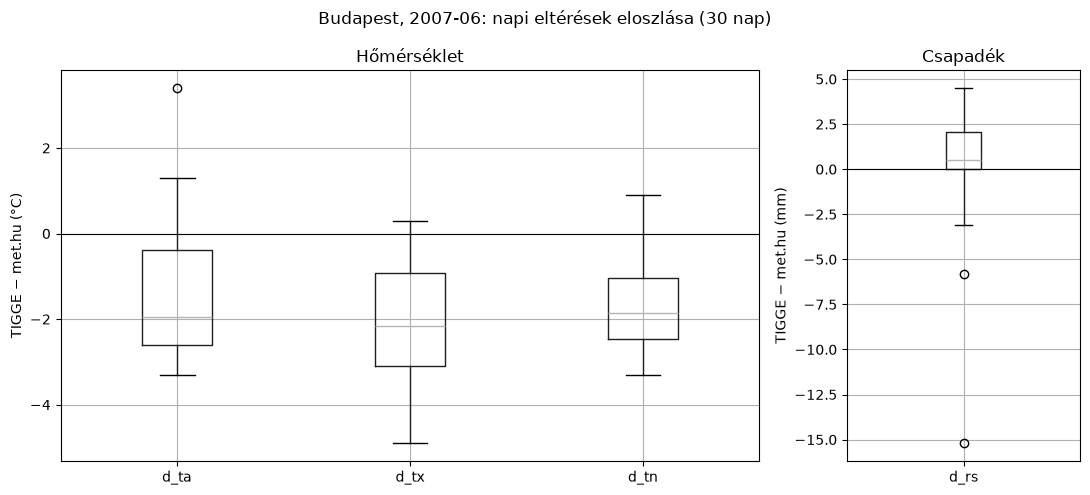

In [17]:
fig, (ax_t, ax_p) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [3, 1]})

m[["d_ta", "d_tx", "d_tn"]].boxplot(ax=ax_t)
ax_t.axhline(0, color="black", lw=0.8)
ax_t.set_ylabel("TIGGE − met.hu (°C)")
ax_t.set_title("Hőmérséklet")

m[["d_rs"]].boxplot(ax=ax_p)
ax_p.axhline(0, color="black", lw=0.8)
ax_p.set_ylabel("TIGGE − met.hu (mm)")
ax_p.set_title("Csapadék")

fig.suptitle(f"Budapest, 2007-06: napi eltérések eloszlása ({len(m)} nap)")
plt.tight_layout()
plt.show()

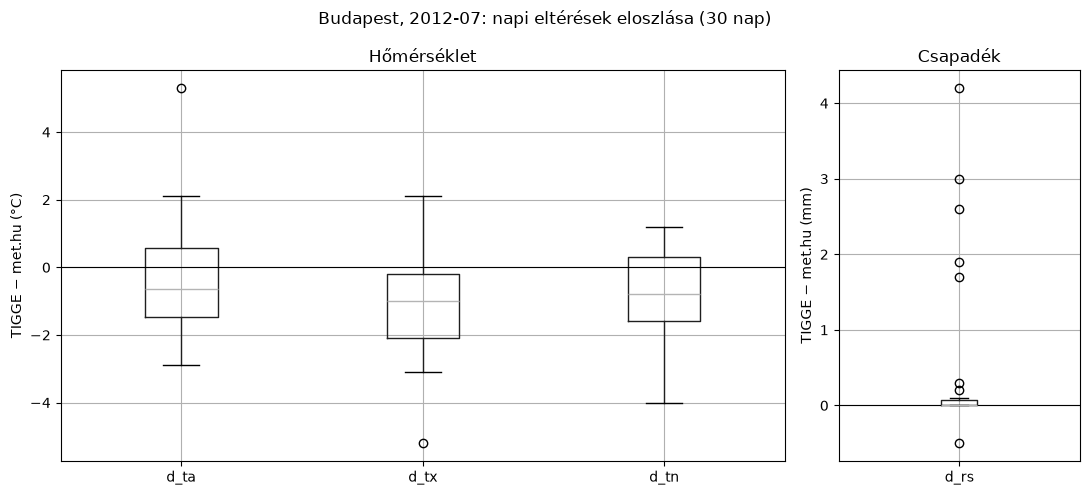

In [18]:
m = diffs.loc["2012-09"]

fig, (ax_t, ax_p) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [3, 1]})

m[["d_ta", "d_tx", "d_tn"]].boxplot(ax=ax_t)
ax_t.axhline(0, color="black", lw=0.8)
ax_t.set_ylabel("TIGGE − met.hu (°C)")
ax_t.set_title("Hőmérséklet")

m[["d_rs"]].boxplot(ax=ax_p)
ax_p.axhline(0, color="black", lw=0.8)
ax_p.set_ylabel("TIGGE − met.hu (mm)")
ax_p.set_title("Csapadék")

fig.suptitle(f"Budapest, 2012-07: napi eltérések eloszlása ({len(m)} nap)")
plt.tight_layout()

In [19]:

print("Függvényesítsük!")

def plot_month(diffs, year, month, city="Budapest"):
    # Szűrés külön változóba
    m = diffs[
        (diffs.index.year == year) &
        (diffs.index.month == month)
    ]

    if m.empty:
        print("A hónapról nincs adatunk!")
        return

    fig, (ax_t, ax_p) = plt.subplots(
        1, 2,
        figsize=(11, 5),
        gridspec_kw={"width_ratios": [3, 1]}
    )

    m[["d_ta", "d_tx", "d_tn"]].boxplot(ax=ax_t)
    ax_t.axhline(0, color="black", lw=0.8)
    ax_t.set_ylabel("TIGGE − met.hu (°C)")
    ax_t.set_title("Hőmérséklet")

    m[["d_rs"]].boxplot(ax=ax_p)
    ax_p.axhline(0, color="black", lw=0.8)
    ax_p.set_ylabel("TIGGE − met.hu (mm)")
    ax_p.set_title("Csapadék")

    fig.suptitle(
        f"{city}, {year}-{month:02d}: "
        f"napi eltérések eloszlása ({len(m)} nap)"
    )

    plt.tight_layout()
    plt.show()


Függvényesítsük!


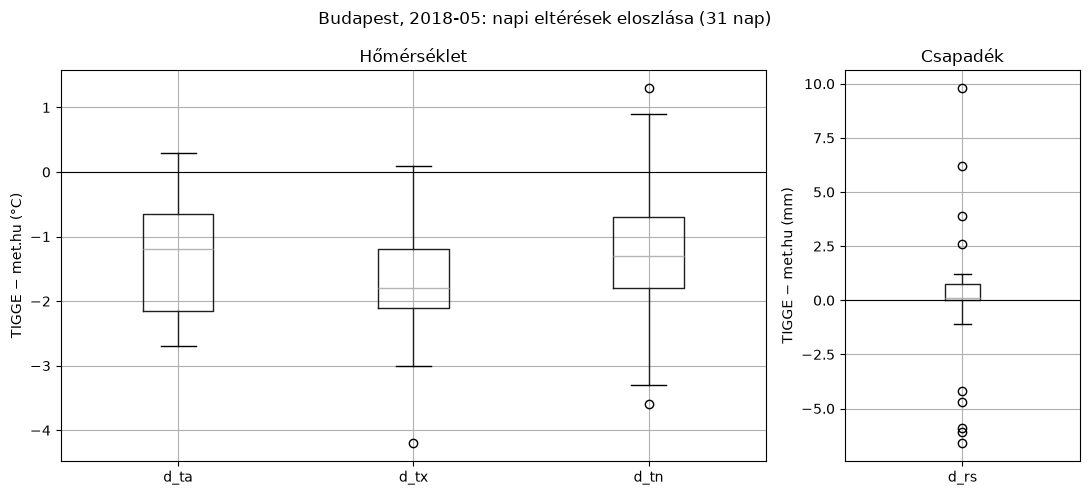

In [20]:
plot_month(diffs,2018,5)

Na ez tök jó, releváns dolgokat látunk. 

Célünk az, hogy az eltéréseket összesítve és városonként is tudjuk átláthatóan mérni. Bevezetünk erre egy vagy több metrikát!

MAE = Mean Average Error, az abszolút eltérések átlaga egy napon

RMSE = Root Mean Squared Error,  mint az MAE, de a nagy kiugrásokat jobban bünteti

Ami még fontos lesz nekünk, az az eltérések szórása. Észrevehetünk egy állandó eltolást, ami következhet abból hogy a rácspont nem az állomás, de ha például egyik napon -3 a mások napon +5 az eltérés, az már az előrejelzés megbízhatatlanságáról szól.

In [21]:
diffs.describe()

,d_ta,d_tx,d_tn,d_rs
count,6271.000000,6271.000000,6271.000000,6271.000000
mean,-1.148334,-0.367836,-1.670483,0.362941
std,1.367446,2.722945,1.445269,3.557288
min,-8.900000,-8.000000,-13.000000,-93.300000
25%,-2.000000,-2.300000,-2.500000,0.000000
50%,-1.200000,-1.100000,-1.600000,0.000000
75%,-0.400000,1.100000,-0.700000,0.600000
max,6.100000,11.300000,5.500000,34.800000


In [22]:
print(f"Budapest MAE napi középhőmérséklet: {float(diffs["d_ta"].abs().mean())}")
print(f"Budapest RMSE napi középhőmérséklet: {float((diffs["d_ta"] ** 2).mean() ** 0.5) }")
print(f"Szórás: {float(diffs["d_ta"].std())}")

Budapest MAE napi középhőmérséklet: 1.4705469622069844
Budapest RMSE napi középhőmérséklet: 1.7855753642114642
Szórás: 1.367445614913631


In [23]:
for col in ["d_ta","d_tx"]:
    print(f"{col}: {diffs[col].abs().mean()}")

d_ta: 1.4705469622069844
d_tx: 2.2884547918992184


Konzultáció után célirányosan haladunk tovább.

In [24]:
print(merged.head())

       datum  d_ta_tigge  d_tx_tigge  d_tn_tigge  d_rs_tigge  d_ta_methu  \
0 2006-10-01        17.4        23.4        11.3         0.0        18.5   
1 2006-10-02        17.6        23.0        12.2         0.0        19.5   
2 2006-10-03        20.6        24.7        16.5         2.9        21.1   
3 2006-10-04        18.4        22.5        14.4         0.2        17.7   
4 2006-10-05        15.6        18.7        12.5         0.0        15.7   

   d_tx_methu  d_tn_methu  d_rs_methu  d_ta_diff  d_tx_diff  d_tn_diff  \
0        24.7        12.9         0.0       -1.1       -1.3       -1.6   
1        25.1        14.5         0.0       -1.9       -2.1       -2.3   
2        26.7        15.4         0.0       -0.5       -2.0        1.1   
3        23.9        15.6         0.0        0.7       -1.4       -1.2   
4        19.1        13.2         0.0       -0.1       -0.4       -0.7   

   d_rs_diff  
0        0.0  
1        0.0  
2        2.9  
3        0.2  
4        0.0  


# 2: Delta számítások

In [25]:
DELTA_PATH = Path(f"{PROJECT_PATH}/delta_methods")
DELTA_PATH.mkdir(exist_ok=True)

In [26]:
def read_daily(path):
    df = pd.read_csv(path, sep=";", skiprows=1, header=None,
                     usecols=range(5), names=["datum", "d_ta", "d_tx", "d_tn", "d_rs"])
    df["datum"] = pd.to_datetime(df["datum"])
    for col in ["d_ta", "d_tx", "d_tn", "d_rs"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

Ez a módszer egy napi, dimenzió nélküli hibaszám, ami a négy mennyiség eltéréset egy közös skálára hozza
1: Abszolút hiba mennyiségenént | Tigge - Methu |

2: Osztás a mérés szórásával: Ezt az abszolút hibát elosztja a met.hu mérés szórásával, ami az adott városra, az adott mennyiségre és az adott naptári hónapra vonatkozik.

3: A 4 szám átlaga, a négy normalizált hibát átlagolja

In [27]:
variables = ["d_ta", "d_tx", "d_tn", "d_rs"]

methu_files = {
    "Budapest": "BP_d.txt",
    "Debrecen": "DE_d.txt",
    "Pécs": "PE_d.txt",
    "Szeged": "SZE_d.txt",
    "Szombathely": "SZO_d.txt",
}

for city, methu_file in methu_files.items():
    t = read_daily(f"{OUT_PATH}/{city}_final.txt")
    o = read_daily(f"{METHU_PATH}/{methu_file}")

    sigma = o.groupby(o["datum"].dt.month)[variables].std()

    m = t.merge(o, on = "datum", how = "inner", suffixes=("_tigge","_methu"))
    month = m["datum"].dt.month

    norm_error = pd.DataFrame(index=m.index)

    for v in variables:
        error = (m[f"{v}_tigge"] - m[f"{v}_methu"]).abs()
        norm_error[v] = error / month.map(sigma[v])

    m["delta"] = norm_error.mean(axis=1, skipna=False).round(3)

    out = m[["datum"] + [f"{v}_{s}" for v in variables for s in ("tigge", "methu")] + ["delta"]]
    out = out.rename(columns={"datum": "#datum"})
    out.to_csv(f"{DELTA_PATH}/{city}_osszevetes.txt", sep=";", index=False, date_format="%Y-%m-%d")

    print(city, len(out), "sor, átlagos delta:", round(m["delta"].mean(), 3))

Budapest 6271 sor, átlagos delta: 0.426
Debrecen 6271 sor, átlagos delta: 0.291
Pécs 6271 sor, átlagos delta: 0.277
Szeged 6271 sor, átlagos delta: 0.324
Szombathely 6271 sor, átlagos delta: 0.325


Új delta: Euklédeszi távolság

In [28]:
print(merged)

          datum  d_ta_tigge  d_tx_tigge  d_tn_tigge  d_rs_tigge  d_ta_methu  \
0    2006-10-01        17.4        23.4        11.3         0.0        18.5   
1    2006-10-02        17.6        23.0        12.2         0.0        19.5   
2    2006-10-03        20.6        24.7        16.5         2.9        21.1   
3    2006-10-04        18.4        22.5        14.4         0.2        17.7   
4    2006-10-05        15.6        18.7        12.5         0.0        15.7   
...         ...         ...         ...         ...         ...         ...   
6266 2024-12-27         2.2         6.4        -2.0         0.1         2.2   
6267 2024-12-28         1.3         5.1        -2.5         0.0         2.2   
6268 2024-12-29        -0.2         3.3        -3.6         0.0        -0.3   
6269 2024-12-30        -0.9         2.0        -3.8         0.0        -1.1   
6270 2024-12-31        -1.4        -0.5        -2.2         0.0        -1.7   

      d_tx_methu  d_tn_methu  d_rs_methu  d_ta_diff

In [29]:
merged_n = merged.copy()

for v in ["d_ta","d_tx","d_tn","d_rs"]:
    for src in ["tigge", "methu"]:
        col = f"{v}_{src}"
        merged_n[col] = merged_n[col] / merged_n[col].mean()

print(merged_n)

          datum  d_ta_tigge  d_tx_tigge  d_tn_tigge  d_rs_tigge  d_ta_methu  \
0    2006-10-01    1.447282    1.417023    1.500306    0.000000    1.404615   
1    2006-10-02    1.463918    1.392801    1.619799    0.000000    1.480540   
2    2006-10-03    1.713449    1.495747    2.190712    1.590427    1.602021   
3    2006-10-04    1.530460    1.362522    1.911894    0.109685    1.343875   
4    2006-10-05    1.297564    1.132407    1.659630    0.000000    1.192025   
...         ...         ...         ...         ...         ...         ...   
6266 2024-12-27    0.182990    0.387562   -0.265541    0.054842    0.167035   
6267 2024-12-28    0.108130    0.308838   -0.331926    0.000000    0.167035   
6268 2024-12-29   -0.016635    0.199837   -0.477974    0.000000   -0.022778   
6269 2024-12-30   -0.074859    0.121113   -0.504528    0.000000   -0.083518   
6270 2024-12-31   -0.116448   -0.030278   -0.292095    0.000000   -0.129073   

      d_tx_methu  d_tn_methu  d_rs_methu  d_ta_diff

In [30]:
merged_n["delta"] = 0
print(merged_n.head(10))

       datum  d_ta_tigge  d_tx_tigge  d_tn_tigge  d_rs_tigge  d_ta_methu  \
0 2006-10-01    1.447282    1.417023    1.500306    0.000000    1.404615   
1 2006-10-02    1.463918    1.392801    1.619799    0.000000    1.480540   
2 2006-10-03    1.713449    1.495747    2.190712    1.590427    1.602021   
3 2006-10-04    1.530460    1.362522    1.911894    0.109685    1.343875   
4 2006-10-05    1.297564    1.132407    1.659630    0.000000    1.192025   
5 2006-10-06    1.089621    1.065795    1.128549    0.000000    1.093322   
6 2006-10-07    1.031397    1.108185    0.863008    0.054842    1.062952   
7 2006-10-08    1.131209    1.108185    1.181657    0.000000    1.154062   
8 2006-10-09    0.989808    1.108185    0.730237    0.000000    1.078137   
9 2006-10-10    1.039714    1.162686    0.770069    0.000000    1.116100   

   d_tx_methu  d_tn_methu  d_rs_methu  d_ta_diff  d_tx_diff  d_tn_diff  \
0    1.463155    1.401826    0.000000       -1.1       -1.3       -1.6   
1    1.486850  

In [31]:
""" for index, row in merged_n.iterrows():
    row["delta"] = math.sqrt(pow(row["d_ta_tigge"] - row["d_ta_methu"], 2) + pow(row["d_tx_tigge"] - row["d_tx_methu"], 2) + pow(row["d_tn_tigge"] - row["d_tn_methu"], 2) + pow(row["d_rs_tigge"] - row["d_rs_methu"], 2)) """

' for index, row in merged_n.iterrows():\n    row["delta"] = math.sqrt(pow(row["d_ta_tigge"] - row["d_ta_methu"], 2) + pow(row["d_tx_tigge"] - row["d_tx_methu"], 2) + pow(row["d_tn_tigge"] - row["d_tn_methu"], 2) + pow(row["d_rs_tigge"] - row["d_rs_methu"], 2)) '

In [32]:
merged_n["delta"] = (
    (merged_n["d_ta_tigge"] - merged_n["d_ta_methu"]) ** 2
    + (merged_n["d_tx_tigge"] - merged_n["d_tx_methu"]) ** 2
    + (merged_n["d_tn_tigge"] - merged_n["d_tn_methu"]) ** 2
    + (merged_n["d_rs_tigge"] - merged_n["d_rs_methu"]) ** 2
) ** 0.5

In [33]:
print(merged_n.head(10))

       datum  d_ta_tigge  d_tx_tigge  d_tn_tigge  d_rs_tigge  d_ta_methu  \
0 2006-10-01    1.447282    1.417023    1.500306    0.000000    1.404615   
1 2006-10-02    1.463918    1.392801    1.619799    0.000000    1.480540   
2 2006-10-03    1.713449    1.495747    2.190712    1.590427    1.602021   
3 2006-10-04    1.530460    1.362522    1.911894    0.109685    1.343875   
4 2006-10-05    1.297564    1.132407    1.659630    0.000000    1.192025   
5 2006-10-06    1.089621    1.065795    1.128549    0.000000    1.093322   
6 2006-10-07    1.031397    1.108185    0.863008    0.054842    1.062952   
7 2006-10-08    1.131209    1.108185    1.181657    0.000000    1.154062   
8 2006-10-09    0.989808    1.108185    0.730237    0.000000    1.078137   
9 2006-10-10    1.039714    1.162686    0.770069    0.000000    1.116100   

   d_tx_methu  d_tn_methu  d_rs_methu  d_ta_diff  d_tx_diff  d_tn_diff  \
0    1.463155    1.401826    0.000000       -1.1       -1.3       -1.6   
1    1.486850  

In [ ]:
merged_n["datum"] = pd.to_datetime(merged_n["datum"])

monthly = merged_n.groupby(merged_n["datum"].dt.month)["delta"].agg(["mean", "median", "std", "count"]).round(3)
monthly.index.name = "honap"
print(monthly)

        mean  median    std  count
honap                             
1      0.756   0.463  1.056    527
2      0.760   0.469  0.871    481
3      0.738   0.411  1.054    527
4      0.637   0.346  0.879    510
5      1.317   0.450  2.334    527
6      1.598   0.499  2.819    510
7      1.461   0.502  2.755    527
8      1.554   0.435  3.998    558
9      1.000   0.340  2.500    540
10     0.781   0.315  1.582    527
11     0.747   0.341  1.180    510
12     0.715   0.397  1.083    527


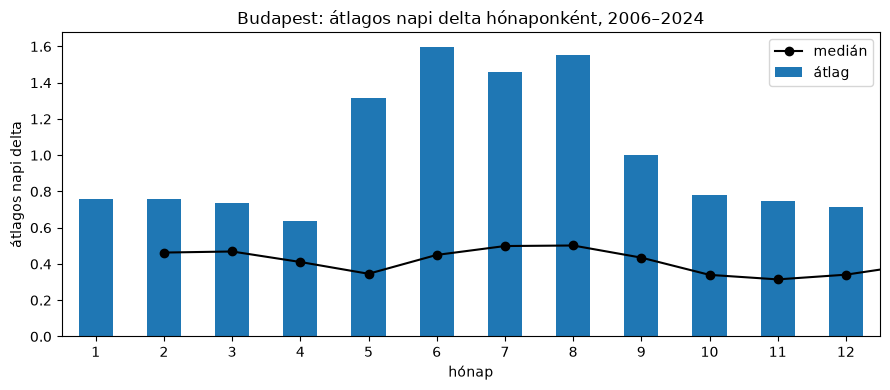

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))
monthly["mean"].plot(kind="bar", ax=ax, label="átlag")
monthly["median"].plot(kind="line", marker="o", color="black", ax=ax, label="median")
ax.set_xlabel("hónap")
ax.set_ylabel("average dailya")
ax.set_title("Budapest: átlagos napi delta hónaponként, 2006–2024")
ax.legend()
plt.tight_layout()
plt.show()

Nézzük meg még gyors csak Debrecenbe

In [36]:
df_methu = read_file(f"{METHU_PATH}/DE_d.txt")
df_tigge = read_file(f"{OUT_PATH}/Debrecen_final.txt")

In [37]:
print(merged.head(10))

       datum  d_ta_tigge  d_tx_tigge  d_tn_tigge  d_rs_tigge  d_ta_methu  \
0 2006-10-01        17.4        23.4        11.3         0.0        18.5   
1 2006-10-02        17.6        23.0        12.2         0.0        19.5   
2 2006-10-03        20.6        24.7        16.5         2.9        21.1   
3 2006-10-04        18.4        22.5        14.4         0.2        17.7   
4 2006-10-05        15.6        18.7        12.5         0.0        15.7   
5 2006-10-06        13.1        17.6         8.5         0.0        14.4   
6 2006-10-07        12.4        18.3         6.5         0.1        14.0   
7 2006-10-08        13.6        18.3         8.9         0.0        15.2   
8 2006-10-09        11.9        18.3         5.5         0.0        14.2   
9 2006-10-10        12.5        19.2         5.8         0.0        14.7   

   d_tx_methu  d_tn_methu  d_rs_methu  d_ta_diff  d_tx_diff  d_tn_diff  \
0        24.7        12.9         0.0       -1.1       -1.3       -1.6   
1        25.1  

In [38]:
merged = df_tigge.merge(df_methu, on="datum", how="inner", suffixes=("_tigge", "_methu"))

print(merged.head(10))

       datum  d_ta_tigge  d_tx_tigge  d_tn_tigge  d_rs_tigge  d_ta_methu  \
0 2006-10-01        17.2        23.8        10.6         0.0        17.3   
1 2006-10-02        19.1        24.2        13.9         0.3        18.6   
2 2006-10-03        21.4        25.1        17.8         0.0        20.6   
3 2006-10-04        22.5        25.4        19.7        13.4        19.7   
4 2006-10-05        16.5        19.3        13.8         0.0        14.1   
5 2006-10-06        14.2        18.8         9.6         0.0        12.8   
6 2006-10-07        12.2        18.7         5.7         0.0        12.1   
7 2006-10-08        12.6        18.4         6.8         0.0        12.2   
8 2006-10-09        12.5        18.3         6.7         0.0        12.1   
9 2006-10-10        12.7        19.2         6.3         0.0        12.8   

   d_tx_methu  d_tn_methu  d_rs_methu  
0        24.9        10.6         0.0  
1        25.1        12.7         0.0  
2        26.3        15.5         0.0  
3  

In [39]:
merged_n = merged.copy()

for v in ["d_ta","d_tx","d_tn","d_rs"]:
    for src in ["tigge", "methu"]:
        col = f"{v}_{src}"
        merged_n[col] = merged_n[col] / merged_n[col].mean()

merged_n["delta"] = 0

merged_n["delta"] = (
    (merged_n["d_ta_tigge"] - merged_n["d_ta_methu"]) ** 2
    + (merged_n["d_tx_tigge"] - merged_n["d_tx_methu"]) ** 2
    + (merged_n["d_tn_tigge"] - merged_n["d_tn_methu"]) ** 2
    + (merged_n["d_rs_tigge"] - merged_n["d_rs_methu"]) ** 2
) ** 0.5

merged_n["datum"] = pd.to_datetime(merged_n["datum"])

monthly = merged_n.groupby(merged_n["datum"].dt.month)["delta"].agg(["mean", "median", "std", "count"]).round(3)
monthly.index.name = "honap"
print(monthly)

        mean  median    std  count
honap                             
1      0.682   0.384  0.905    527
2      0.644   0.333  1.035    481
3      0.641   0.294  1.176    527
4      0.824   0.315  1.412    510
5      1.175   0.418  1.832    527
6      1.494   0.408  2.695    510
7      1.526   0.340  3.163    527
8      1.043   0.222  2.857    558
9      0.939   0.265  1.874    540
10     0.704   0.273  1.530    527
11     0.728   0.297  1.191    510
12     0.743   0.325  1.511    527


In [41]:
print(merged_n.head(10))

       datum  d_ta_tigge  d_tx_tigge  d_tn_tigge  d_rs_tigge  d_ta_methu  \
0 2006-10-01    1.400371    1.411160    1.376966    0.000000    1.453949   
1 2006-10-02    1.555063    1.434877    1.805644    0.168399    1.563205   
2 2006-10-03    1.742322    1.488240    2.312263    0.000000    1.731292   
3 2006-10-04    1.831881    1.506028    2.559078    7.521810    1.655653   
4 2006-10-05    1.343379    1.144344    1.792653    0.000000    1.185011   
5 2006-10-06    1.156120    1.114698    1.247063    0.000000    1.075754   
6 2006-10-07    0.993286    1.108769    0.740444    0.000000    1.016924   
7 2006-10-08    1.025853    1.090981    0.883336    0.000000    1.025328   
8 2006-10-09    1.017712    1.085052    0.870346    0.000000    1.016924   
9 2006-10-10    1.033995    1.138415    0.818385    0.000000    1.075754   

   d_tx_methu  d_tn_methu  d_rs_methu     delta  
0    1.451669    1.496817    0.000000  0.137390  
1    1.463329    1.793356    0.000000  0.171420  
2    1.533289

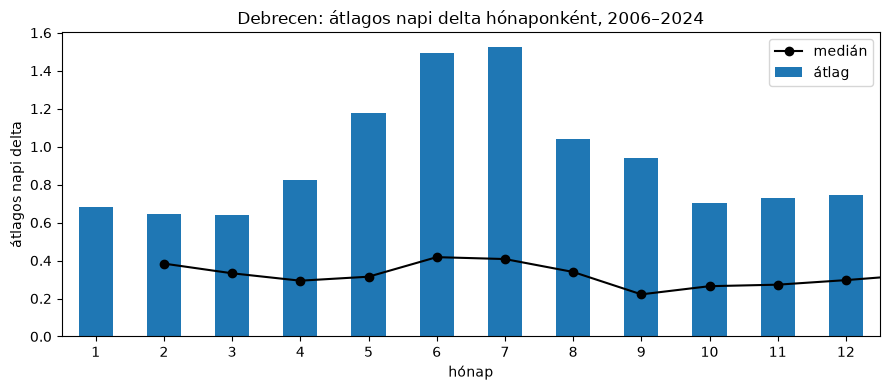

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
monthly["mean"].plot(kind="bar", ax=ax, label="átlag")
monthly["median"].plot(kind="line", marker="o", color="black", ax=ax, label="medián")
ax.set_xlabel("hónap")
ax.set_ylabel("átlagos napi delta")
ax.set_title("Debrecen: átlagos napi delta hónaponként, 2006–2024")
ax.legend()
plt.tight_layout()
plt.show()

In [42]:
print(merged_n.head(10))

       datum  d_ta_tigge  d_tx_tigge  d_tn_tigge  d_rs_tigge  d_ta_methu  \
0 2006-10-01    1.400371    1.411160    1.376966    0.000000    1.453949   
1 2006-10-02    1.555063    1.434877    1.805644    0.168399    1.563205   
2 2006-10-03    1.742322    1.488240    2.312263    0.000000    1.731292   
3 2006-10-04    1.831881    1.506028    2.559078    7.521810    1.655653   
4 2006-10-05    1.343379    1.144344    1.792653    0.000000    1.185011   
5 2006-10-06    1.156120    1.114698    1.247063    0.000000    1.075754   
6 2006-10-07    0.993286    1.108769    0.740444    0.000000    1.016924   
7 2006-10-08    1.025853    1.090981    0.883336    0.000000    1.025328   
8 2006-10-09    1.017712    1.085052    0.870346    0.000000    1.016924   
9 2006-10-10    1.033995    1.138415    0.818385    0.000000    1.075754   

   d_tx_methu  d_tn_methu  d_rs_methu     delta  
0    1.451669    1.496817    0.000000  0.137390  
1    1.463329    1.793356    0.000000  0.171420  
2    1.533289

In [48]:
csapadek = merged_n[["datum","d_rs_tigge", "d_rs_methu"]].copy()
print(csapadek.head(10))

       datum  d_rs_tigge  d_rs_methu
0 2006-10-01    0.000000    0.000000
1 2006-10-02    0.168399    0.000000
2 2006-10-03    0.000000    0.000000
3 2006-10-04    7.521810    8.304935
4 2006-10-05    0.000000    0.070381
5 2006-10-06    0.000000    0.000000
6 2006-10-07    0.000000    0.000000
7 2006-10-08    0.000000    0.000000
8 2006-10-09    0.000000    0.000000
9 2006-10-10    0.000000    0.000000


In [49]:
csapadek["delta"] = 0
print(csapadek)

          datum  d_rs_tigge  d_rs_methu  delta
0    2006-10-01    0.000000    0.000000      0
1    2006-10-02    0.168399    0.000000      0
2    2006-10-03    0.000000    0.000000      0
3    2006-10-04    7.521810    8.304935      0
4    2006-10-05    0.000000    0.070381      0
...         ...         ...         ...    ...
6266 2024-12-27    0.000000    0.000000      0
6267 2024-12-28    0.000000    0.000000      0
6268 2024-12-29    0.056133    0.000000      0
6269 2024-12-30    0.056133    0.000000      0
6270 2024-12-31    0.056133    0.000000      0

[6271 rows x 4 columns]


In [53]:
csapadek["delta"] = (
    (csapadek["d_rs_tigge"] - csapadek["d_rs_methu"]) ** 2) ** 0.5

csapadek["datum"] = pd.to_datetime(csapadek["datum"])

monthly_rs = csapadek.groupby(csapadek["datum"].dt.month)["delta"].agg(["mean", "median", "std", "count"]).round(3)
monthly_rs.index.name = "honap"
print(monthly_rs)

        mean  median    std  count
honap                             
1      0.526   0.152  0.954    527
2      0.500   0.112  1.077    481
3      0.503   0.056  1.216    527
4      0.704   0.112  1.458    510
5      1.087   0.283  1.873    527
6      1.399   0.291  2.736    510
7      1.425   0.168  3.202    527
8      0.925   0.000  2.890    558
9      0.819   0.015  1.917    540
10     0.555   0.000  1.572    527
11     0.595   0.056  1.241    510
12     0.613   0.112  1.547    527


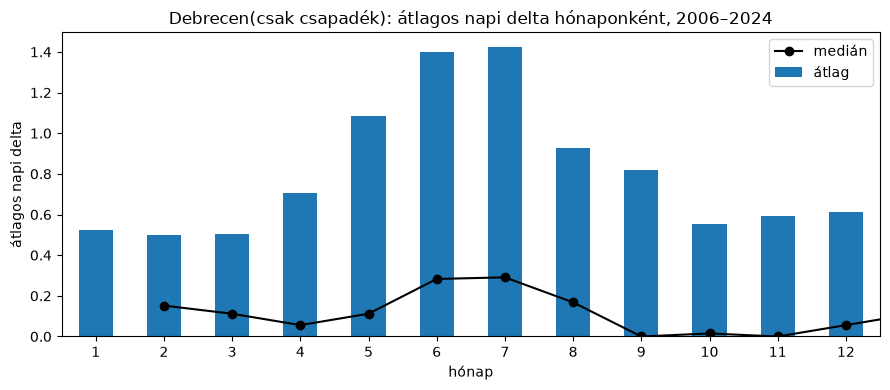

In [55]:
fig, ax = plt.subplots(figsize=(9, 4))
monthly_rs["mean"].plot(kind="bar", ax=ax, label="átlag")
monthly_rs["median"].plot(kind="line", marker="o", color="black", ax=ax, label="medián")
ax.set_xlabel("hónap")
ax.set_ylabel("átlagos napi delta")
ax.set_title("Debrecen(csak csapadék): átlagos napi delta hónaponként, 2006–2024")
ax.legend()
plt.tight_layout()
plt.show()